# Eksplorasi Dataset Shopee Product Listings (Rebrowser)

**Riset:** Optimasi Pemilihan Produk dan Harga Jual bagi Seller Shopee Berdasarkan Prediksi Permintaan

Notebook ini berisi eksplorasi data awal untuk pengajuan riset kepada dosen. Urutan bagian:

0. Konfigurasi dan pemuatan data
1. Identitas dan struktur dataset
2. Kualitas data
3. Variabel target (proxy permintaan)
4. Kandidat fitur
5. Hubungan awal fitur dan target
6. Uji awal kelayakan dengan model baseline
7. Ringkasan untuk dosen

**Cara pakai:** dataset diunduh otomatis dari Kaggle (`rebrowser/shopee-dataset`) melalui `kagglehub`, sehingga tidak perlu menyiapkan file CSV secara manual. Cukup jalankan semua sel secara berurutan (Run All). Semua tabel dan grafik tersimpan di folder `hasil_eksplorasi`.

## 0. Konfigurasi dan Pemuatan Data

### 0.1 Impor pustaka dan konfigurasi

Sel ini menentukan nama kolom penting dan proxy permintaan yang dipakai. Sesuaikan bagian KONFIGURASI jika nama kolom berbeda. Lokasi data tidak lagi diatur di sini karena diunduh dari Kaggle pada langkah 0.2.

In [21]:
import glob
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# ---------------- KONFIGURASI ----------------
KAGGLE_DATASET = "rebrowser/shopee-dataset"  # sumber data di Kaggle
OUTPUT_DIR = "hasil_eksplorasi"       # folder untuk grafik dan tabel
ID_COL = "itemId"
PREMIUM_TOKEN = "[PREMIUM]"
PROXY_COLS = ["ratingCount", "commentCount", "likedCount"]  # kandidat proxy permintaan
TARGET = "ratingCount"                # proxy permintaan utama
NUM_COLS = ["priceMin", "priceMax", "ratingAvg", "ratingCount",
            "commentCount", "likedCount", "shippingFeeMin", "discount"]
TITLE_CANDIDATES = ["title", "name", "itemName"]
RANDOM_STATE = 42
# ---------------------------------------------

os.makedirs(OUTPUT_DIR, exist_ok=True)

### 0.2 Mengunduh dataset dari Kaggle

Dataset diunduh langsung dari Kaggle dengan `kagglehub` dan disimpan di cache lokal (unduhan berikutnya tidak diulang). Variabel `DATA_GLOB` dibentuk otomatis dari lokasi hasil unduhan: jika ada folder `product-details`, hanya CSV di folder itu yang dipakai, jika tidak semua CSV di dataset dipakai.

**Yang diperiksa:** lokasi unduhan dan pola file yang terbentuk. Jika Kaggle meminta autentikasi, buat API token di Kaggle (Settings > API) lalu jalankan `kagglehub.login()` atau isi variabel lingkungan `KAGGLE_USERNAME` dan `KAGGLE_KEY`.

In [22]:
%pip install -q kagglehub

import kagglehub

DATASET_PATH = kagglehub.dataset_download(KAGGLE_DATASET)
print("Dataset diunduh ke:", DATASET_PATH)

# Utamakan folder product-details; jika tidak ada, pakai semua CSV pada dataset
pola_utama = os.path.join(DATASET_PATH, "**", "product-details", "*.csv")
pola_semua = os.path.join(DATASET_PATH, "**", "*.csv")
DATA_GLOB = pola_utama if glob.glob(pola_utama, recursive=True) else pola_semua
print("Pola file yang dipakai:", DATA_GLOB)


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Dataset diunduh ke: C:\Users\fasya\.cache\kagglehub\datasets\rebrowser\shopee-dataset\versions\212
Pola file yang dipakai: C:\Users\fasya\.cache\kagglehub\datasets\rebrowser\shopee-dataset\versions\212\**\*.csv


### 0.3 Memuat dan menggabungkan file harian

Seluruh file CSV harian digabung menjadi satu DataFrame `df`. Tanggal snapshot diambil dari nama file dan disimpan pada kolom `snapshot_date`.

**Yang diperiksa:** jumlah file yang terbaca dan ukuran data gabungan harus sesuai dengan yang Anda harapkan (30 file, 1.000 baris per file).

In [23]:
files = sorted(glob.glob(DATA_GLOB, recursive=True))
if not files:
    kandidat = sorted(glob.glob(pola_semua, recursive=True))
    print("Folder dataset       :", DATASET_PATH)
    print("Pola yang dicari     :", DATA_GLOB)
    print(f"File CSV di folder dataset ({len(kandidat)}):")
    for k in kandidat[:20]:
        print("  ", k)
    raise FileNotFoundError(
        "Tidak ada file CSV yang cocok di dataset hasil unduhan Kaggle.")

frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    m = re.search(r"\d{4}-\d{2}-\d{2}", os.path.basename(f))
    d["snapshot_date"] = m.group(0) if m else os.path.basename(f)
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
print(f"Jumlah file dimuat: {len(files)}")
print(f"Ukuran gabungan  : {df.shape[0]:,} baris x {df.shape[1]} kolom")

Jumlah file dimuat: 30
Ukuran gabungan  : 30,000 baris x 53 kolom


## 1. Identitas dan Struktur Dataset

### 1.1 Cakupan dan keunikan produk

**Yang diperiksa:** jumlah baris per snapshot dan jumlah `itemId` unik. Jika tidak ada `itemId` yang muncul lebih dari satu kali, data bersifat cross-sectional (satu pengamatan per produk), sehingga perubahan nilai antarhari tidak dapat dihitung. Hal ini perlu disebut sebagai keterbatasan.

In [24]:
print("\n=== Baris per snapshot ===")
print(df.groupby("snapshot_date").size().describe())

print("\n=== Keunikan produk ===")
if ID_COL in df.columns:
    n_unique = df[ID_COL].nunique()
    n_repeat = int((df[ID_COL].value_counts() > 1).sum())
    print(f"itemId unik                    : {n_unique:,}")
    print(f"itemId muncul lebih dari 1 kali: {n_repeat:,}")
    print("Jika nilai terakhir = 0, data bersifat cross-sectional "
          "(tidak ada deret waktu per produk).")
else:
    print(f"Kolom {ID_COL} tidak ditemukan. Periksa nama kolom ID.")


=== Baris per snapshot ===
count      30.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0
dtype: float64

=== Keunikan produk ===
itemId unik                    : 30,000
itemId muncul lebih dari 1 kali: 0
Jika nilai terakhir = 0, data bersifat cross-sectional (tidak ada deret waktu per produk).


### 1.2 Tipe data dan contoh baris

**Yang diperiksa:** tipe data setiap kolom, apakah kolom yang seharusnya numerik terbaca sebagai teks, dan contoh nilai pada tiap kolom. Cocokkan dengan dokumentasi field dataset.

In [25]:
print("\n=== Tipe data tiap kolom ===")
print(df.dtypes.to_string())

print("\n=== Contoh 5 baris pertama ===")
print(df.head())


=== Tipe data tiap kolom ===
_primaryKey               float64
_firstSeenAt                  str
_lastSeenAt                   str
itemId                      int64
shopId                      int64
title                         str
description                   str
status                        str
condition                   int64
catId                     float64
categories                    str
brand                      object
brandId                   float64
currency                      str
price                         str
priceMin                  float64
priceMax                  float64
priceBeforeDiscount           str
priceMinBeforeDiscount        str
priceMaxBeforeDiscount        str
discount                  float64
ratingAvg                 float64
ratingCount               float64
commentCount              float64
likedCount                float64
shopLocation               object
isAdult                    object
isPreOrder                 object
estimatedDays     

## 2. Kualitas Data

### 2.1 Tabel missing value dan kolom terkunci

Tabel ini menghitung persentase nilai kosong (`NaN`) dan nilai terkunci (`[PREMIUM]`) pada setiap kolom, lalu memisahkan kolom yang tidak layak (90% atau lebih tidak terpakai) dan kolom yang layak (kurang dari 20%).

**Hasil yang dibawa ke dosen:** tabel ini menjadi dasar alasan mengapa kolom seperti `price`, `priceBeforeDiscount`, `models`, `discount`, dan `isFreeShipping` tidak dipakai.

In [26]:
n = len(df)
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_premium": df.isin([PREMIUM_TOKEN]).sum(),
    "n_unique": df.nunique(dropna=True),
})
quality["pct_missing"] = (quality["n_missing"] / n * 100).round(2)
quality["pct_premium"] = (quality["n_premium"] / n * 100).round(2)
quality["pct_tidak_terpakai"] = quality["pct_missing"] + quality["pct_premium"]
quality = quality.sort_values("pct_tidak_terpakai", ascending=False)
quality.to_csv(os.path.join(OUTPUT_DIR, "tabel_kualitas_data.csv"))

print("=== Kolom dengan data kosong / terkunci (urut terbesar) ===")
print(quality[quality["pct_tidak_terpakai"] > 0].to_string())

unusable = quality[quality["pct_tidak_terpakai"] >= 90].index.tolist()
usable = quality[quality["pct_tidak_terpakai"] < 20].index.tolist()
print(f"\nKolom tidak layak (>=90% kosong/terkunci): {unusable}")
print(f"Kolom layak (<20% kosong/terkunci)       : {usable}")

=== Kolom dengan data kosong / terkunci (urut terbesar) ===
                          dtype  n_missing  n_premium  n_unique  pct_missing  pct_premium  pct_tidak_terpakai
priceBeforeDiscount         str          0      30000         1         0.00        100.0              100.00
price                       str          0      30000         1         0.00        100.0              100.00
priceMaxBeforeDiscount      str          0      30000         1         0.00        100.0              100.00
priceMinBeforeDiscount      str          0      30000         1         0.00        100.0              100.00
models                      str          0      30000         1         0.00        100.0              100.00
isIndividualSeller      float64      30000          0         0       100.00          0.0              100.00
productUrl                  str          0      30000         1         0.00        100.0              100.00
isMart                  float64      30000          0       

### 2.2 Duplikat

**Yang diperiksa:** baris duplikat penuh dan duplikat pada `itemId`. Duplikat pada `itemId` dapat menyebabkan kebocoran data saat pembagian data latih dan uji.

In [27]:
# Duplikat
cols_cek = [c for c in df.columns if c != "snapshot_date"]
print(f"\nBaris duplikat penuh      : {int(df.duplicated(subset=cols_cek).sum()):,}")
if ID_COL in df.columns:
    print(f"Baris duplikat pada itemId: {int(df.duplicated(subset=[ID_COL]).sum()):,}")


Baris duplikat penuh      : 0
Baris duplikat pada itemId: 0


### 2.3 Konversi kolom numerik

Token `[PREMIUM]` dan teks yang tidak valid diubah menjadi `NaN` pada salinan data (`clean`). Sel ini melaporkan jumlah nilai yang gagal dikonversi.

**Yang diperiksa:** jika banyak nilai yang berubah menjadi `NaN`, kemungkinan format kolom (misalnya `ratingCount`) tidak berupa angka tunggal dan perlu diurai terlebih dahulu.

In [28]:
# Konversi kolom numerik (token PREMIUM dan teks tak valid menjadi NaN)
clean = df.copy()
for c in NUM_COLS:
    if c in clean.columns:
        before = clean[c].notna().sum()
        clean[c] = pd.to_numeric(clean[c].replace(PREMIUM_TOKEN, np.nan),
                                 errors="coerce")
        after = clean[c].notna().sum()
        if before != after:
            print(f"[info] {c}: {before - after:,} nilai non-numerik dijadikan NaN")

### 2.4 Stabilitas antar snapshot

**Yang diperiksa:** apakah median harga, proxy permintaan, dan rating relatif stabil antar tanggal. Jika stabil, penggabungan seluruh snapshot dapat dipertanggungjawabkan.

In [29]:
# Stabilitas antar snapshot
cek_cols = [c for c in ["priceMin", TARGET, "ratingAvg"] if c in clean.columns]
if cek_cols:
    print("\n=== Median per snapshot (stabilitas distribusi) ===")
    print(clean.groupby("snapshot_date")[cek_cols].median().describe().loc[["min", "50%", "max"]])


=== Median per snapshot (stabilitas distribusi) ===
       priceMin  ratingCount  ratingAvg
min  27300000.0          0.0        0.0
50%  39375000.0          0.0        0.0
max  59000000.0          2.0        5.0


## 3. Variabel Target (Proxy Permintaan)

Karena dataset tidak memiliki kolom jumlah terjual, permintaan diukur dengan proxy. Bagian ini menguji kelayakan proxy tersebut.

### 3.1 Ringkasan statistik proxy

**Yang diperiksa:** rata-rata, median, persentil, proporsi nilai nol, dan skewness. Proporsi nol yang tinggi dan skewness yang besar menunjukkan perlunya transformasi log atau pendekatan klasifikasi.

In [30]:
proxy_cols = [c for c in PROXY_COLS if c in clean.columns]
print(f"Proxy tersedia: {proxy_cols}")

rows = []
for c in proxy_cols:
    x = clean[c].dropna()
    rows.append({
        "proxy": c,
        "n_non_null": len(x),
        "rata2": x.mean(),
        "median": x.median(),
        "p90": x.quantile(0.90),
        "p99": x.quantile(0.99),
        "maks": x.max(),
        "pct_nol": (x == 0).mean() * 100,
        "skewness": x.skew(),
    })
proxy_summary = pd.DataFrame(rows).set_index("proxy").round(3)
print("\n=== Ringkasan statistik proxy ===")
print(proxy_summary.to_string())
proxy_summary.to_csv(os.path.join(OUTPUT_DIR, "ringkasan_proxy.csv"))

Proxy tersedia: ['ratingCount', 'commentCount', 'likedCount']

=== Ringkasan statistik proxy ===
              n_non_null   rata2  median  p90     p99     maks  pct_nol  skewness
proxy                                                                            
ratingCount        27030  16.892     0.0  7.0  229.71  48545.0   77.262    87.369
commentCount       28523  11.208     0.0  6.0  209.78  17687.0   78.610    67.026
likedCount         28523   9.099     0.0  8.0  157.00   9133.0   74.431    45.834


### 3.2 Distribusi proxy

Histogram kiri menunjukkan data asli (dipotong pada persentil ke-99 agar terbaca), histogram kanan menunjukkan distribusi setelah transformasi `log(1 + x)`.

**Yang diperiksa:** apakah transformasi log membuat distribusi lebih simetris.

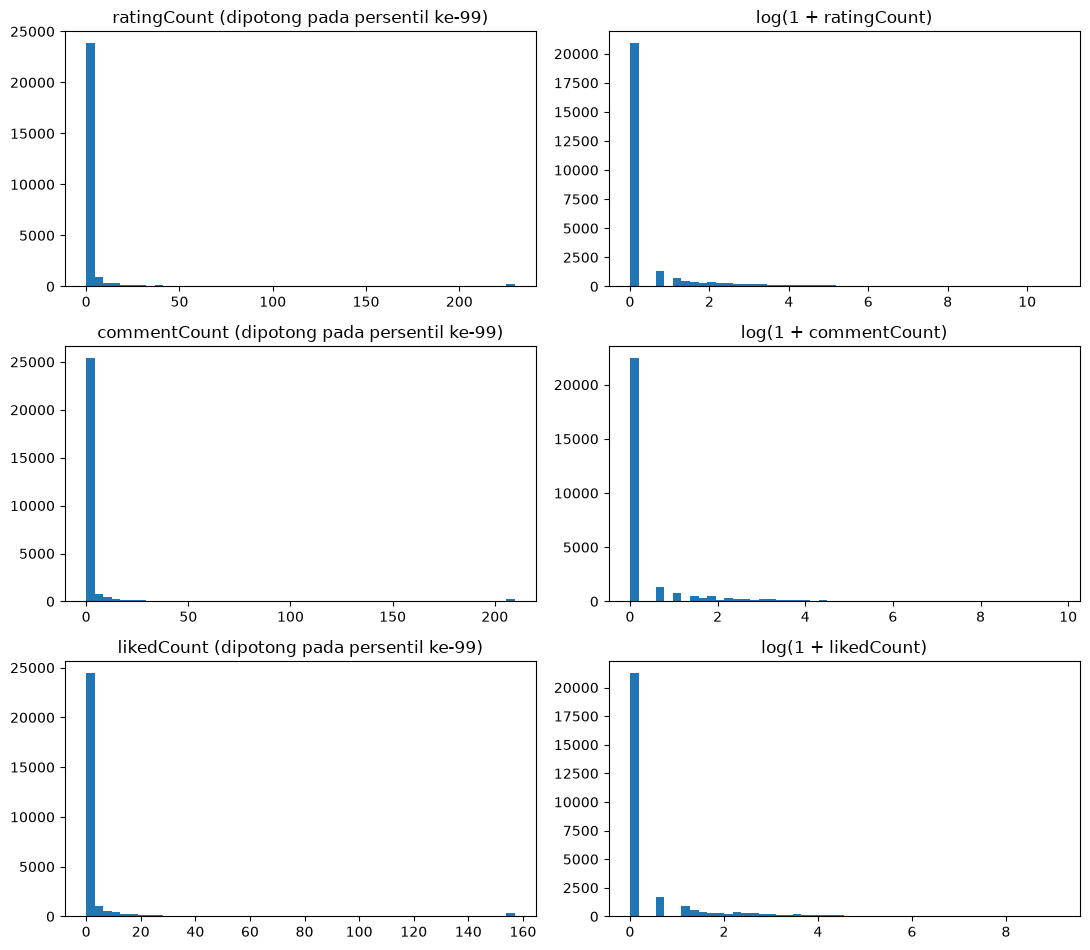

In [31]:
if proxy_cols:
    fig, axes = plt.subplots(len(proxy_cols), 2,
                             figsize=(11, 3.2 * len(proxy_cols)), squeeze=False)
    for i, c in enumerate(proxy_cols):
        x = clean[c].dropna()
        if x.empty:
            continue
        axes[i, 0].hist(x.clip(upper=x.quantile(0.99)), bins=50)
        axes[i, 0].set_title(f"{c} (dipotong pada persentil ke-99)")
        axes[i, 1].hist(np.log1p(x), bins=50)
        axes[i, 1].set_title(f"log(1 + {c})")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "distribusi_proxy.png"), dpi=150)
    plt.show()

### 3.3 Korelasi antar proxy

Korelasi Spearman antar `ratingCount`, `commentCount`, dan `likedCount`.

**Yang diperiksa:** korelasi tinggi menunjukkan ketiganya mengukur hal yang serupa, sehingga pemilihan satu proxy utama dapat dibenarkan.

In [32]:
if len(proxy_cols) >= 2:
    print("\n=== Korelasi Spearman antar proxy ===")
    print(clean[proxy_cols].corr(method="spearman").round(3))
    print("Korelasi tinggi menunjukkan proxy mengukur hal yang serupa.")


=== Korelasi Spearman antar proxy ===
              ratingCount  commentCount  likedCount
ratingCount         1.000         0.993       0.820
commentCount        0.993         1.000       0.784
likedCount          0.820         0.784       1.000
Korelasi tinggi menunjukkan proxy mengukur hal yang serupa.


## 4. Kandidat Fitur

### 4.1 Harga

Kolom `price` terkunci, sehingga `priceMin` dipakai sebagai harga acuan dan `priceMax - priceMin` sebagai indikator variasi harga antar varian.

**Yang diperiksa:** harga nol atau negatif, kasus `priceMin > priceMax`, jumlah outlier, dan skala nilai harga (nilai yang sangat besar dapat menandakan satuan yang berbeda).

=== Statistik harga acuan (priceMin) ===
count    2.852300e+04
mean     2.083143e+08
std      1.121049e+09
min      1.000000e+05
1%       1.500000e+06
25%      1.610000e+07
50%      3.830000e+07
75%      9.030000e+07
99%      3.835138e+09
max      4.999990e+10
Name: price_ref, dtype: float64

priceMin <= 0            : 0
priceMin > priceMax      : 0
Produk multi-varian harga: 38.3%
Outlier harga (IQR pada log): 1,114
Catatan: nilai harga yang sangat besar dapat menandakan satuan/skala yang berbeda. Periksa sebelum modeling.


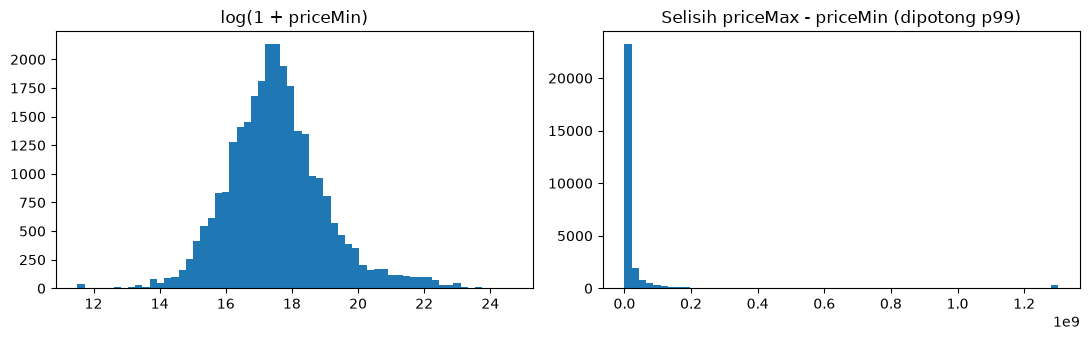

In [33]:
# Harga: price terkunci, gunakan priceMin sebagai harga acuan.
if {"priceMin", "priceMax"} <= set(clean.columns):
    clean["price_ref"] = clean["priceMin"]
    clean["price_range"] = clean["priceMax"] - clean["priceMin"]
    clean["is_multi_variant"] = clean["price_range"] > 0
    clean["log_price"] = np.log1p(clean["price_ref"].clip(lower=0))

    print("=== Statistik harga acuan (priceMin) ===")
    print(clean["price_ref"].describe(percentiles=[.01, .25, .5, .75, .99]).round(2))
    print(f"\npriceMin <= 0            : {int((clean['priceMin'] <= 0).sum()):,}")
    print(f"priceMin > priceMax      : {int((clean['priceMin'] > clean['priceMax']).sum()):,}")
    print(f"Produk multi-varian harga: {clean['is_multi_variant'].mean() * 100:.1f}%")

    lp = clean["log_price"].dropna()
    q1, q3 = lp.quantile(.25), lp.quantile(.75)
    iqr = q3 - q1
    n_out = int(((lp < q1 - 1.5 * iqr) | (lp > q3 + 1.5 * iqr)).sum())
    print(f"Outlier harga (IQR pada log): {n_out:,}")
    print("Catatan: nilai harga yang sangat besar dapat menandakan satuan/skala "
          "yang berbeda. Periksa sebelum modeling.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].hist(lp, bins=60)
    axes[0].set_title("log(1 + priceMin)")
    pr = clean["price_range"].dropna()
    if not pr.empty:
        axes[1].hist(pr.clip(upper=pr.quantile(0.99)), bins=60)
    axes[1].set_title("Selisih priceMax - priceMin (dipotong p99)")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "distribusi_harga.png"), dpi=150)
    plt.show()
else:
    print("priceMin/priceMax tidak ditemukan. Periksa nama kolom harga.")

### 4.2 Reputasi, lokasi toko, dan judul

**Yang diperiksa:** distribusi `ratingAvg` (nilai 0 umumnya menandakan produk tanpa ulasan), jumlah kategori `shopLocation`, dan ketersediaan kolom judul untuk fitur turunan seperti panjang judul.

In [34]:
# Reputasi
if "ratingAvg" in clean.columns:
    print("\n=== ratingAvg ===")
    print(clean["ratingAvg"].describe().round(3))
    print(f"ratingAvg = 0: {(clean['ratingAvg'] == 0).mean() * 100:.1f}% "
          "(kemungkinan produk tanpa ulasan)")

# Lokasi toko
if "shopLocation" in clean.columns:
    print(f"\n=== shopLocation: {clean['shopLocation'].nunique()} kategori ===")
    print(clean["shopLocation"].value_counts().head(15))

# Panjang judul (jika ada)
title_col = next((c for c in TITLE_CANDIDATES if c in clean.columns), None)
if title_col:
    clean["title_len"] = clean[title_col].astype(str).str.len()
    print(f"\nKolom judul terdeteksi: {title_col}")


=== ratingAvg ===
count    28523.000
mean         1.070
std          2.042
min          0.000
25%          0.000
50%          0.000
75%          0.000
max          5.000
Name: ratingAvg, dtype: float64
ratingAvg = 0: 74.6% (kemungkinan produk tanpa ulasan)

=== shopLocation: 141 kategori ===
shopLocation
桃園市蘆竹區    758
桃園市大園區    130
桃園市楊梅區     34
臺北市中山區     29
臺南市東區      29
新北市三重區     24
臺北市中正區     24
臺中市大雅區     21
桃園市中壢區     20
高雄市仁武區     19
桃園市龜山區     19
桃園市大溪區     18
桃園市八德區     18
新北市板橋區     15
臺南市永康區     13
Name: count, dtype: int64

Kolom judul terdeteksi: title


### 4.3 Kolom lain yang masih terisi

Daftar kolom yang layak dipakai tetapi belum dibahas di atas. Gunakan untuk mencari fitur tambahan, misalnya kategori produk atau informasi toko.

In [35]:
# Penjelajahan kolom lain yang terisi (cari fitur tambahan)
print("\n=== Kolom lain yang terisi (kandidat fitur tambahan) ===")
sudah_dibahas = set(NUM_COLS) | {ID_COL, "shopLocation", "snapshot_date", title_col}
tambahan = [c for c in usable if c not in sudah_dibahas]
print(df[tambahan].dtypes.to_string() if tambahan else "(tidak ada)")


=== Kolom lain yang terisi (kandidat fitur tambahan) ===
description              str
shopResponseRate     float64
shopResponseTime     float64
catId                float64
createdAt                str
shopRatingGood       float64
shopCreatedAt            str
shopRatingBad        float64
shopRatingNormal     float64
shopName                 str
shopItemCount        float64
shopRating           float64
shopFollowerCount    float64
currency                 str
isOfficialShop        object
isShopeeVerified      object
isServiceByShopee     object
status                   str
_lastSeenAt              str
shopId                 int64
condition              int64
categories               str
_primaryKey          float64
_firstSeenAt             str
images                   str
modelsCount            int64


## 5. Hubungan Awal Fitur dan Target

### 5.1 Korelasi fitur dengan target

Korelasi Spearman dipakai karena data condong dan banyak bernilai nol.

**Perhatian:** jika target adalah `ratingCount`, `ratingAvg` tidak boleh dipakai sebagai fitur prediksi karena dihitung dari ulasan yang sama (kebocoran data).

In [36]:
assert TARGET in clean.columns, f"Kolom target {TARGET} tidak ditemukan."

feat_num = [c for c in ["log_price", "price_range", "ratingAvg",
                        "shippingFeeMin", "title_len"] if c in clean.columns]
corr_cols = feat_num + [c for c in proxy_cols if c != TARGET]
corr_target = (clean[corr_cols + [TARGET]]
               .corr(method="spearman")[TARGET].drop(TARGET).round(3))
print(f"=== Korelasi Spearman terhadap {TARGET} ===")
print(corr_target.sort_values(key=abs, ascending=False).to_string())
if TARGET == "ratingCount" and "ratingAvg" in feat_num:
    print("PERINGATAN: ratingAvg dihitung dari ulasan yang sama dengan ratingCount. "
          "Jangan dipakai sebagai fitur prediksi bila target = ratingCount.")

=== Korelasi Spearman terhadap ratingCount ===
commentCount      0.993
ratingAvg         0.974
likedCount        0.820
shippingFeeMin   -0.185
price_range      -0.185
log_price        -0.093
title_len         0.086
PERINGATAN: ratingAvg dihitung dari ulasan yang sama dengan ratingCount. Jangan dipakai sebagai fitur prediksi bila target = ratingCount.


### 5.2 Harga terhadap proxy permintaan

Scatter plot harga terhadap target, tabel permintaan per kuintil harga, dan boxplot per kuintil.

**Yang diperiksa:** ada atau tidaknya pola antara harga dan permintaan. Ingat bahwa hubungan ini bersifat asosiatif, bukan kausal.

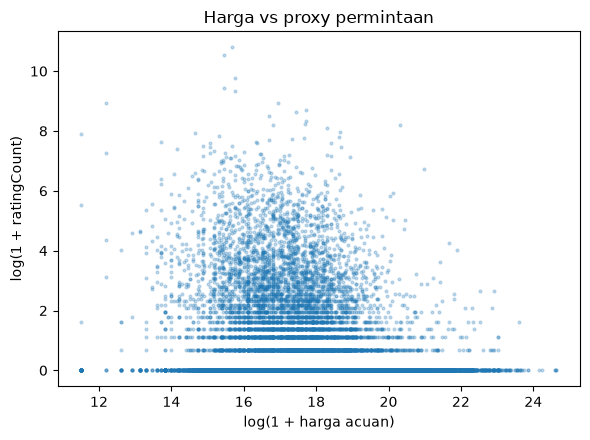


=== ratingCount menurut kuintil harga ===
                                 n  rata2  median  pct_nol
price_bin                                                 
(99999.999, 12900000.0]       5549  46.48     0.0    69.81
(12900000.0, 28200000.0]      5493  13.94     0.0    73.78
(28200000.0, 51000000.0]      5434  10.54     0.0    75.49
(51000000.0, 119300000.0]     5405   7.02     0.0    73.21
(119300000.0, 49999900000.0]  5149   5.22     0.0    73.83


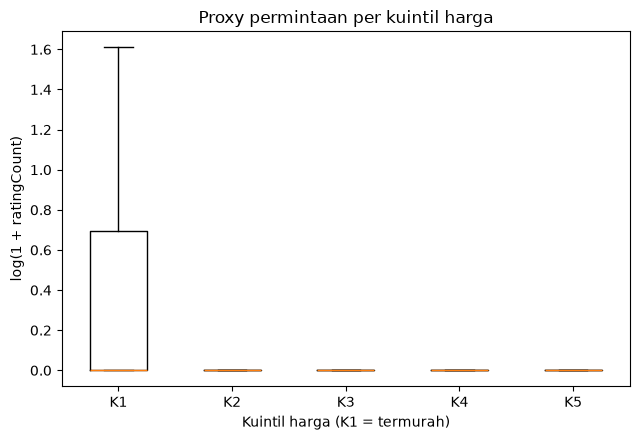

In [37]:
# Scatter harga vs target
if "log_price" in clean.columns:
    tmp = clean[["log_price", TARGET]].dropna()
    plt.figure(figsize=(6, 4.5))
    plt.scatter(tmp["log_price"], np.log1p(tmp[TARGET]), s=4, alpha=0.25)
    plt.xlabel("log(1 + harga acuan)")
    plt.ylabel(f"log(1 + {TARGET})")
    plt.title("Harga vs proxy permintaan")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "scatter_harga_vs_target.png"), dpi=150)
    plt.show()

    # Permintaan menurut kuintil harga
    clean["price_bin"] = pd.qcut(clean["price_ref"], 5, duplicates="drop")
    by_bin = (clean.groupby("price_bin", observed=True)[TARGET]
              .agg(n="count", rata2="mean", median="median",
                   pct_nol=lambda s: (s == 0).mean() * 100).round(2))
    print(f"\n=== {TARGET} menurut kuintil harga ===")
    print(by_bin.to_string())
    by_bin.to_csv(os.path.join(OUTPUT_DIR, "target_per_kuintil_harga.csv"))

    groups = [np.log1p(g[TARGET].dropna())
              for _, g in clean.groupby("price_bin", observed=True)]
    plt.figure(figsize=(6.5, 4.5))
    plt.boxplot(groups, showfliers=False)
    plt.xticks(range(1, len(groups) + 1),
               [f"K{i + 1}" for i in range(len(groups))])
    plt.xlabel("Kuintil harga (K1 = termurah)")
    plt.ylabel(f"log(1 + {TARGET})")
    plt.title("Proxy permintaan per kuintil harga")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "boxplot_target_per_kuintil.png"), dpi=150)
    plt.show()

### 5.3 Permintaan menurut lokasi toko

**Yang diperiksa:** apakah lokasi toko berasosiasi dengan perbedaan permintaan yang berarti.

In [38]:
# Permintaan menurut lokasi toko
if "shopLocation" in clean.columns:
    top_loc = clean["shopLocation"].value_counts().head(10).index
    by_loc = (clean[clean["shopLocation"].isin(top_loc)]
              .groupby("shopLocation")[TARGET]
              .agg(n="count", median="median", rata2="mean",
                   pct_nol=lambda s: (s == 0).mean() * 100)
              .sort_values("n", ascending=False).round(2))
    print(f"\n=== {TARGET} menurut 10 lokasi toko terbanyak ===")
    print(by_loc.to_string())


=== ratingCount menurut 10 lokasi toko terbanyak ===
               n  median  rata2  pct_nol
shopLocation                            
桃園市蘆竹區        33     0.0   0.00     4.35
新北市三重區         6     0.0   0.17    20.83
臺北市中山區         5     0.0   8.60    10.34
臺中市大雅區         3     0.0   8.33     9.52
桃園市中壢區         2     0.0   0.00    10.00
桃園市楊梅區         2     1.5   1.50     2.94
桃園市大園區         2     0.0   0.00     1.54
臺北市中正區         2     3.5   3.50     4.17
臺南市東區          1     0.0   0.00     3.45
高雄市仁武區         1     0.0   0.00     5.26


## 6. Uji Awal Kelayakan dengan Model Baseline

Tujuan bagian ini adalah melihat apakah fitur memiliki daya prediksi di atas baseline sederhana. Hasilnya bersifat eksploratif, bukan model akhir.

### 6.1 Persiapan fitur dan target

Target ditransformasi dengan `log(1 + x)`. Fitur terdiri atas harga acuan (log), selisih harga, ongkir minimum, panjang judul, dan lokasi toko (10 terbanyak, sisanya "Lainnya"). `ratingAvg` dikecualikan otomatis bila target adalah `ratingCount`.

In [39]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

feats = [c for c in ["log_price", "price_range", "shippingFeeMin", "title_len"]
         if c in clean.columns]
# Hindari kebocoran: ratingAvg hanya dipakai bila target bukan ratingCount.
if "ratingAvg" in clean.columns and TARGET != "ratingCount":
    feats.append("ratingAvg")

X = clean[feats].copy()
if "shopLocation" in clean.columns:
    top_loc = clean["shopLocation"].value_counts().head(10).index
    loc = clean["shopLocation"].where(clean["shopLocation"].isin(top_loc), "Lainnya")
    X = pd.concat([X, pd.get_dummies(loc, prefix="loc", dtype=float)], axis=1)
X = X.fillna(X.median(numeric_only=True))

y = np.log1p(clean[TARGET])
valid = y.notna()
X, y = X[valid], y[valid]
print(f"Fitur model ({X.shape[1]}): {list(X.columns)}")
print(f"Jumlah observasi: {len(y):,}")

ImportError: DLL load failed while importing _random: An Application Control policy has blocked this file.

### 6.2 Fungsi evaluasi

Fungsi ini membagi data 80:20, melatih baseline (median) dan Random Forest, menghitung R², MAE, dan RMSE pada data uji, serta menampilkan pentingnya fitur dengan permutation importance.

In [ ]:
model_results = []

def evaluate(mask, label):
    """Latih baseline dan Random Forest, simpan metrik, tampilkan pentingnya fitur."""
    Xs, ys = X[mask], y[mask]
    if len(ys) < 200:
        print(f"[lewati] {label}: data terlalu sedikit ({len(ys)})")
        return None
    Xtr, Xte, ytr, yte = train_test_split(
        Xs, ys, test_size=0.2, random_state=RANDOM_STATE)
    base = DummyRegressor(strategy="median").fit(Xtr, ytr)
    rf = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5,
        n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, ytr)
    for nama, mdl in [("Baseline (median)", base), ("Random Forest", rf)]:
        p = mdl.predict(Xte)
        model_results.append({
            "skenario": label, "model": nama, "n_uji": len(yte),
            "R2": r2_score(yte, p),
            "MAE": mean_absolute_error(yte, p),
            "RMSE": np.sqrt(mean_squared_error(yte, p)),
        })
    pi = permutation_importance(rf, Xte, yte, n_repeats=5,
                                random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
    print(f"\nPentingnya fitur (permutation) - {label}:")
    print(imp.head(8).round(4).to_string())
    return imp

### 6.3 Menjalankan evaluasi dan membandingkan model

Dua skenario dijalankan: seluruh produk, dan hanya produk dengan target lebih dari nol (karena banyak produk bernilai nol).

**Cara membaca:** R² Random Forest yang jauh di atas baseline menunjukkan fitur punya daya prediksi. Jika R² mendekati nol atau negatif, proxy atau fitur perlu ditinjau ulang sebelum riset diajukan.

In [ ]:
model_results.clear()
evaluate(y.notna(), "Semua produk")
evaluate(y > 0, f"Hanya produk dengan {TARGET} > 0")

res = pd.DataFrame(model_results).round(4)
print("\n=== Perbandingan model (skala log1p) ===")
print(res.to_string(index=False))
res.to_csv(os.path.join(OUTPUT_DIR, "hasil_model_baseline.csv"), index=False)

## 7. Ringkasan untuk Dosen

Ringkasan otomatis berisi ukuran data, jumlah produk unik, kolom yang tidak layak, karakteristik proxy utama, dan perbandingan R² model. Gunakan bersama tabel dan grafik di folder `hasil_eksplorasi`.

In [ ]:
print("=" * 60)
print("RINGKASAN EKSPLORASI")
print("=" * 60)
print(f"Total baris / kolom      : {df.shape[0]:,} / {df.shape[1]}")
if ID_COL in df.columns:
    print(f"Produk unik              : {df[ID_COL].nunique():,}")
print(f"Kolom tidak layak (>=90%): {unusable}")
if TARGET in proxy_summary.index:
    print(f"Proxy utama              : {TARGET} "
          f"(nol: {proxy_summary.loc[TARGET, 'pct_nol']:.1f}%, "
          f"skewness: {proxy_summary.loc[TARGET, 'skewness']:.2f})")
if model_results:
    r = pd.DataFrame(model_results)
    for skenario, g in r.groupby("skenario"):
        b = g[g["model"].str.startswith("Baseline")]["R2"].iloc[0]
        m = g[g["model"] == "Random Forest"]["R2"].iloc[0]
        print(f"R2 [{skenario}]: baseline {b:.3f} -> RF {m:.3f}")
print(f"\nTabel dan grafik tersimpan di folder: {OUTPUT_DIR}/")